# After the fit: quality control, uncertainty and differential expression

Fitting a model gives one parameter set per gene. This notebook shows what Monod
offers for the steps that follow: rejecting genes the model does not describe,
reading the standard errors, and comparing two datasets parameter by parameter
rather than by mean expression.

The two datasets are the **T cells** and **monocytes** of the PBMC 10k
experiment. The same genes are fitted in both, with the `Bursty` transcription
model and no sequencing-noise model, so each gene has three parameters: burst
size *b*, splicing rate *β* and degradation rate *γ* (all log10, in units of the
transcription-burst frequency).

| Section | Function |
|---|---|
| 2 | `perform_inference` on an in-memory `AnnData` |
| 4 | `inference.reject_genes`, `SearchResults.plot_KL`, `plot_gene_distributions` |
| 5 | `SearchResults.compute_sigma`, `plot_param_marg`, `analysis.plot_params_for_pair` |
| 6 | `analysis.DE_parameters` |
| 7 | `analysis.diffexp_mean` |
| 8 | `analysis.compare_gene_distributions` |
| 9 | `AnnData.write_h5ad`, `inference.search_result_from_uns` |

**Data:** `example_h5ad/processed_pbmc_10k_raw.h5ad` (not in the repository).
**Runtime:** under a minute with the Rust accelerator.

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))

In [2]:
import logging, time, warnings
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

from monod import analysis
from monod.cme_toolbox import CMEModel, _HAS_RUST
from monod.inference import (perform_inference, reject_genes,
                             search_result_from_uns, searchdata_from_adata)

logging.getLogger('monod').setLevel(logging.WARNING)   # progress messages off
warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
print(f'Rust backend: {_HAS_RUST}')

Rust backend: True


---
## 1 · Two cell types from one experiment

The processed PBMC 10k object carries raw unspliced and spliced counts and a
cell-type label. Splitting on the label gives two `AnnData` objects that can be
passed straight to `perform_inference`; a file path works equally well. Gene
symbols are moved into the index so that the result tables read naturally.

In [3]:
H5AD_PATH = 'example_h5ad/processed_pbmc_10k_raw.h5ad'
adata = ad.read_h5ad(H5AD_PATH)
adata.var_names = adata.var['gene_name'].astype(str).values
adata.var_names_make_unique()

adata_T = adata[adata.obs['subclass_label'] == 'Tcells'].copy()
adata_M = adata[adata.obs['subclass_label'] == 'Monocytes'].copy()
del adata

print(f'T cells  : {adata_T.n_obs:5,} cells')
print(f'Monocytes: {adata_M.n_obs:5,} cells')

T cells  : 5,375 cells
Monocytes: 3,972 cells


---
## 2 · Fit both datasets

Two arguments matter for what follows:

- `exclude_sigma=False` computes a standard error for every parameter from the
  Hessian at the optimum. The differential-expression test in section 6 uses them.
- `genes_to_fit` forces the second fit onto the genes the first fit selected, so
  the two results line up gene for gene.

With a sequencing-noise model (`Poisson` or `Bernoulli`) the same call would
repeat the fit over a grid of technical parameters and choose the grid point
that minimises the total divergence; `SearchResults.plot_landscape` shows that
grid and `analysis.find_most_concordant_samp` picks a shared point for two
matched datasets. Without a noise model there is a single grid point and those
steps are skipped.

In [4]:
N_GENES = 200
model = CMEModel('Bursty', 'None')

t0 = time.perf_counter()
adata_T = perform_inference(adata_T, model, n_genes=N_GENES, exclude_sigma=False, viz=False,
                            dataset_string='pbmc_T', num_cores=8)
t1 = time.perf_counter()
adata_M = perform_inference(adata_M, model, n_genes=N_GENES, exclude_sigma=False, viz=False,
                            genes_to_fit=list(adata_T.var_names),
                            dataset_string='pbmc_M', num_cores=8)
t2 = time.perf_counter()

assert (adata_T.var_names == adata_M.var_names).all()
print(f'T cells  : {adata_T.n_vars} genes fitted in {t1 - t0:5.1f} s')
print(f'Monocytes: {adata_M.n_vars} genes fitted in {t2 - t1:5.1f} s')

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

optimize_genes_2d_sd: 4/200 genes did not converge (4 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


Grid scan: 100%|██████████| 1/1 [00:00<00:00,  2.30it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  2.29it/s]

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

optimize_genes_2d_sd: 3/200 genes did not converge (3 hit max_iterations, 0 solver errors). Consider raising gradient_params['max_iterations'] or checking the bounds.


Grid scan: 100%|██████████| 1/1 [00:00<00:00,  2.00it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  2.00it/s]

T cells  : 200 genes fitted in   2.3 s
Monocytes: 200 genes fitted in   2.4 s


---
## 3 · What the fit leaves behind

Per-gene results land in `.var`: the log10 parameter estimates under the model's
TeX labels (`$b$`, `$\beta$`, `$\gamma$`), their standard errors (`error_*`) and
the AIC. The complete result is a plain dictionary in `.uns['search_result']`;
`search_result_from_uns` turns it back into a `SearchResults` object, and
`searchdata_from_adata` rebuilds the per-gene histograms that the plotting and
testing methods need.

In [5]:
cols = [c for c in adata_T.var.columns if '$' in c or c == 'AIC']
display(adata_T.var[cols].head(6).round(3))

sr_T, sr_M = (search_result_from_uns(a.uns['search_result']) for a in (adata_T, adata_M))
sd_T, sd_M = (searchdata_from_adata(a) for a in (adata_T, adata_M))
print(f'genes: {sr_T.n_genes}   parameters per gene: {sr_T.sp.n_phys_pars}   '
      f'grid points: {sr_T.sp.n_grid_points}')

,$b$,$\beta$,$\gamma$,AIC,error_$b$,error_$\beta$,error_$\gamma$
PRDM2,0.108,-0.232,0.898,26314.664,0.017,0.016,0.022
RNF11,-0.066,0.160,0.777,16051.455,0.023,0.021,0.027
ZRANB2,-0.486,-0.261,-0.172,21275.674,0.031,0.031,0.032
PCNX2,0.276,0.047,1.174,23110.323,0.017,0.015,0.023
RBBP5,-0.200,0.413,0.602,11404.181,0.030,0.027,0.031
TPM3,-0.028,-0.013,-0.208,32824.653,0.016,0.016,0.016


genes: 200   parameters per gene: 3   grid points: 1


---
## 4 · Goodness of fit and gene rejection

`reject_genes` runs a chi-square test of each gene's observed joint histogram
against its fitted distribution (Bonferroni-corrected, with low-count bins
pooled) and a Hellinger-distance check, then flags the failures in
`.var['rejected_genes']` and inside the stored result. Later functions skip
rejected genes by default (`discard_rejected=True`).

`plot_KL` shows the distribution of per-gene divergences, and
`plot_gene_distributions` the observed and fitted joint distributions. Below,
the top row holds the four worst fits by Hellinger distance and the bottom row
the four best.

T cells   :   2 of 200 genes rejected


Monocytes :   3 of 200 genes rejected


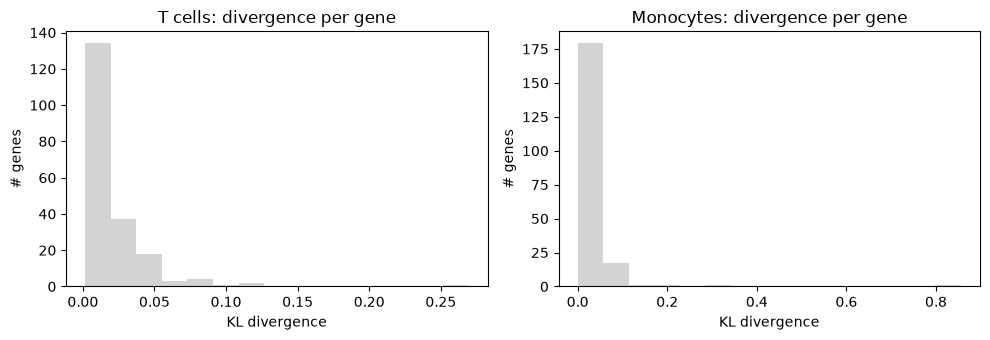

Worst fits: ['CD74', 'RPS19', 'TFDP2', 'RALA']  rejected: [True, True, False, False]
Best fits : ['COMMD5', 'ABCF2', 'TMEM11', 'GABARAPL1']


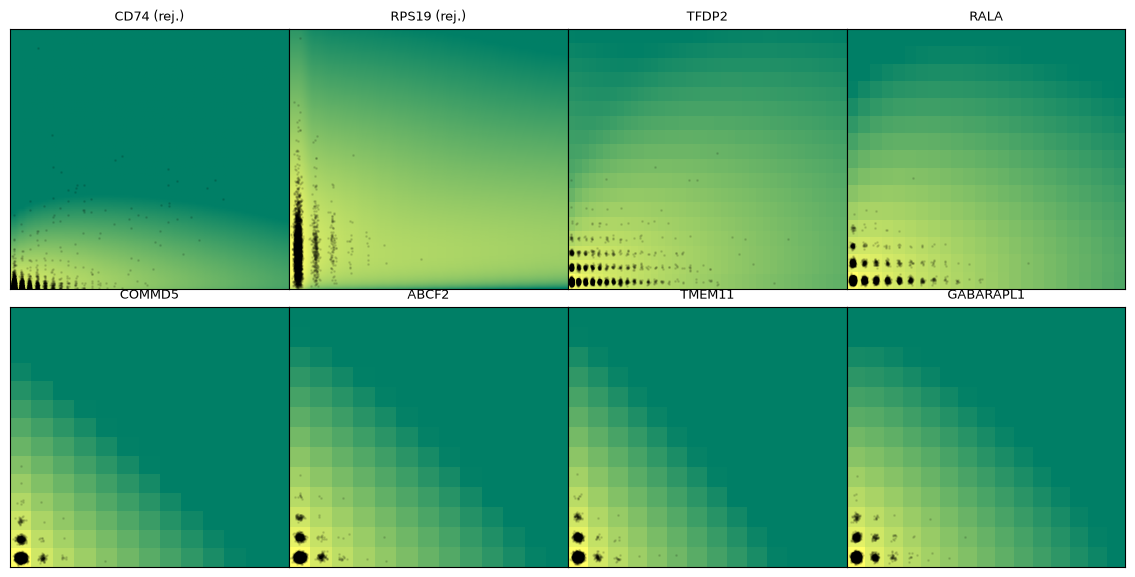

In [6]:
for a, name in ((adata_T, 'T cells'), (adata_M, 'Monocytes')):
    reject_genes(a, viz=False)
    print(f"{name:10s}: {int(a.var['rejected_genes'].sum()):3d} of {a.n_vars} genes rejected")

# Reload the results so the objects carry the rejection flags.
sr_T, sr_M = (search_result_from_uns(a.uns['search_result']) for a in (adata_T, adata_M))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, sr, name in zip(axes, (sr_T, sr_M), ('T cells', 'Monocytes')):
    sr.plot_KL(ax, discard_rejected=False)
    ax.set_title(f'{name}: divergence per gene')
plt.tight_layout(); plt.show()

order = np.argsort(adata_T.var['hellinger'].values)
worst, best = order[-4:][::-1], order[:4]
print('Worst fits:', list(adata_T.var_names[worst]), ' rejected:', [bool(v) for v in adata_T.var['rejected_genes'].values[worst]])
print('Best fits :', list(adata_T.var_names[best]))
sr_T.plot_gene_distributions(sd_T, sz=(2, 4), figsize=(12, 6), marg='joint',
                             genes_to_plot=np.concatenate([worst, best]), savefig=False)
plt.show()

---
## 5 · Parameter uncertainty and the pair plot

`compute_sigma` inverts the Hessian of the divergence at each gene's optimum to
get a local standard error per parameter; `perform_inference` already did this
and stored the values in `.var['error_*']`. `plot_param_marg` shows the
distribution of each parameter across genes, and `plot_params_for_pair` puts
the two datasets against each other with error bars. That picture is what the
differential-expression test in the next section formalises: most genes near
the identity line, possibly with a small common offset, and a few far from it.

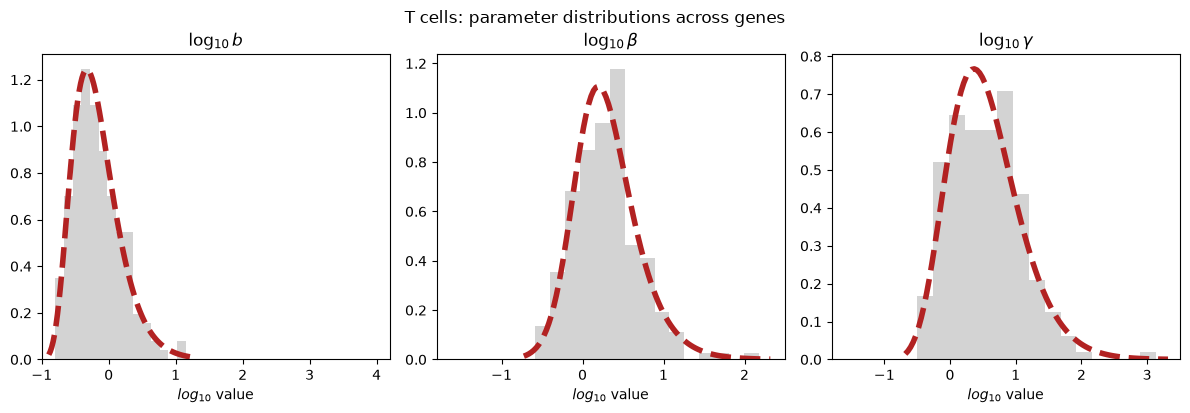

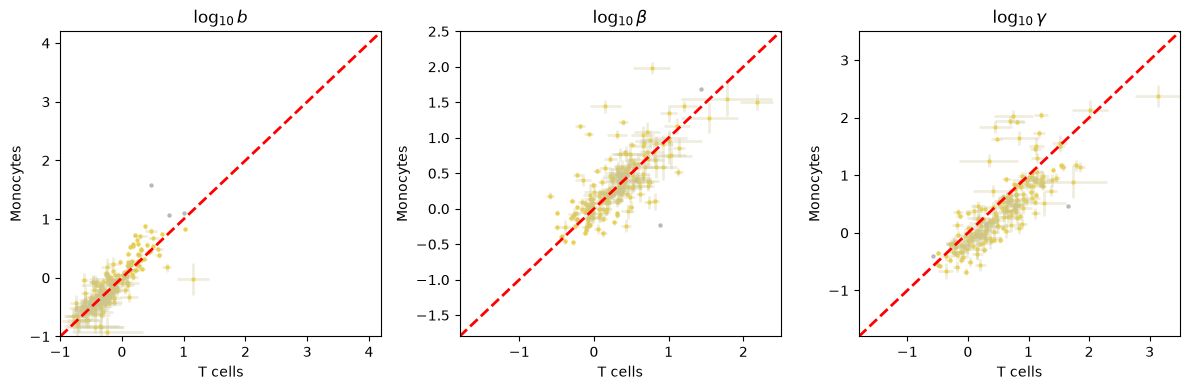

Median standard error (log10 units) per parameter, T cells:
error_$b$           0.029
error_$\beta$       0.028
error_$\gamma$      0.032
error_unreliable    0.000


In [7]:
sr_T.plot_param_marg()
plt.suptitle('T cells: parameter distributions across genes', y=1.02)
plt.show()

fig = analysis.plot_params_for_pair(sr_T, sr_M, plot_errorbars=True,
                                    xlabel='T cells', ylabel='Monocytes', savefig=False)
fig.savefig('figures/analysis_workflow_pair.png', dpi=150, bbox_inches='tight')
plt.show()

err = adata_T.var[[c for c in adata_T.var.columns if c.startswith('error_')]]
print('Median standard error (log10 units) per parameter, T cells:')
print(err.median().round(3).to_string())

---
## 6 · Differential expression, one parameter at a time

`DE_parameters` compares the two fits parameter by parameter. For each parameter
it models the gene-to-gene differences as a Gaussian around a common offset,
weighted by the standard errors, and iterates: genes whose difference is
improbable under that Gaussian are set aside, the Gaussian is refitted on the
rest, and so on. The genes left outside at convergence are called differentially
expressed with respect to that parameter. Rejected genes are excluded first.
The histograms show the residuals after the last round, with the fitted
Gaussian.

It returns the gene names per parameter, a boolean matrix, the fitted offsets and
the residuals, and writes fold changes to both objects: `FC_*` (raw difference),
`adj_FC_*` (difference minus the common offset) and, on the second object,
`adj_*` (its parameters shifted onto the first object's scale).

Fold changes saved to each dataframe under .var, e.g. FC_$\gamma$
Adjusted parameter values (subtracting the average fold change) saved to the second dataframe under .var, e.g. adj_$\gamma$
Adjusted fold changes (subtracting the average fold change) saved to each dataframe under .var, e.g. adj_FC_$\gamma$


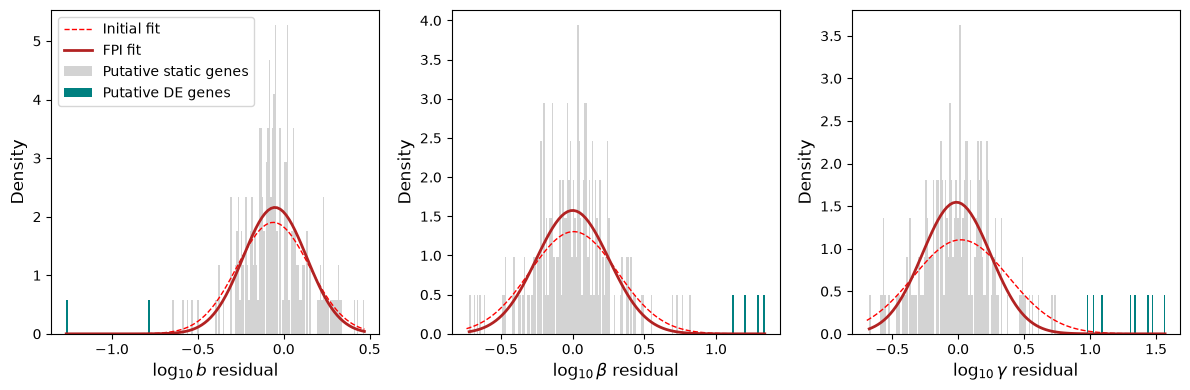

Common offset (monocytes minus T cells, log10): {'$b$': 0.094, '$\\beta$': 0.005, '$\\gamma$': -0.184}
Genes called DE per parameter: {'$b$': 2, '$\\beta$': 4, '$\\gamma$': 8}


,gene,adj_FC_$b$,DE_$b$,adj_FC_$\beta$,DE_$\beta$,adj_FC_$\gamma$,DE_$\gamma$,n_DE
55,LINC00402,0.100,False,1.206,True,1.472,True,2
63,SYNE2,0.071,False,1.114,True,1.339,True,2
132,GRAP2,0.324,False,1.340,True,1.303,True,2
128,UBASH3A,0.204,False,1.289,True,1.568,True,2
21,NMT2,0.023,False,0.728,False,1.444,True,1
112,MEIS1,-1.266,True,-0.682,False,-0.573,False,1
97,FXYD7,-0.265,False,-0.013,False,0.978,True,1
134,CCDC80,-0.787,True,-0.236,False,-0.674,False,1
184,TPD52,0.230,False,0.822,False,1.020,True,1
48,AC005842.1,-0.495,False,-0.048,False,1.090,True,1


In [8]:
gn, gf, offs, resid = analysis.DE_parameters(adata_T, adata_M, use_sigma=True, viz=True)
plt.show()

par_labels = [p.replace(r'\log_{10} ', '') for p in sr_T.model.param_str]
print('Common offset (monocytes minus T cells, log10):',
      {k: round(float(v), 3) for k, v in zip(par_labels, offs[:, 0])})
print('Genes called DE per parameter:', {k: int(v) for k, v in zip(par_labels, gf.sum(1))})

tab = pd.DataFrame({'gene': adata_T.var_names})
for i, lab in enumerate(par_labels):
    tab['adj_FC_' + lab] = adata_M.var['adj_FC_' + lab].values
    tab['DE_' + lab] = gf[i]
rejected = adata_T.var['rejected_genes'].values | adata_M.var['rejected_genes'].values
tab = tab.loc[~rejected].copy()
tab['n_DE'] = tab[[c for c in tab.columns if c.startswith('DE_')]].sum(1)
display(tab.sort_values('n_DE', ascending=False).head(12).round(3))

---
## 7 · Against the mean-expression view

`diffexp_mean` is the conventional comparison on the same cells: a Welch t-test
on size-normalised, log-transformed spliced counts, with a Bonferroni-corrected
threshold and a minimum absolute log2 fold change (`fc_thr`, 1 by default).
The two tests need not agree. The t-test asks whether a gene's mean moved by
more than the threshold; the parameter test asks whether a gene's shift in one
parameter stands out against the shifts of all other genes, after the common
offset is removed. A gene can change burst size and degradation rate in
compensating directions and keep its mean, and a gene whose mean moves along
with most other genes is not singled out by the parameter test.

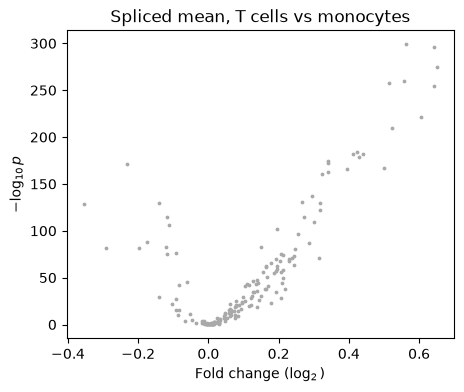

DE in any parameter,False,True
DE by mean (t-test),,
False,179,10
True,8,0


DE in a parameter but not in mean: ['NMT2', 'AC005842.1', 'LINC00402', 'SYNE2', 'FXYD7', 'MEIS1', 'UBASH3A', 'GRAP2', 'CCDC80', 'TPD52']


In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
gf_mean, fc_mean = analysis.diffexp_mean(sd_T, sd_M, method='ttest', viz=True, ax1=ax)
ax.set_title('Spliced mean, T cells vs monocytes')
plt.show()

keep = ~rejected
ct = pd.crosstab(pd.Series(gf_mean[keep], name='DE by mean (t-test)'),
                 pd.Series(gf.any(0)[keep], name='DE in any parameter'))
display(ct)

only_params = tab.loc[(tab['n_DE'] > 0) & ~gf_mean[keep], 'gene'].tolist()
print('DE in a parameter but not in mean:', only_params[:15])

---
## 8 · Look at the genes

`compare_gene_distributions` overlays the two datasets' marginal histograms and
fitted marginals for a chosen set of genes (dataset 1 in blue, dataset 2 in red).
Here: six genes called DE in at least one parameter, ranked by their largest
adjusted change over the three parameters.

,adj_FC_$b$,adj_FC_$\beta$,adj_FC_$\gamma$,n_DE
gene,,,,
UBASH3A,0.20,1.29,1.57,2
LINC00402,0.10,1.21,1.47,2
NMT2,0.02,0.73,1.44,1
GRAP2,0.32,1.34,1.30,2
SYNE2,0.07,1.11,1.34,2
MEIS1,-1.27,-0.68,-0.57,1


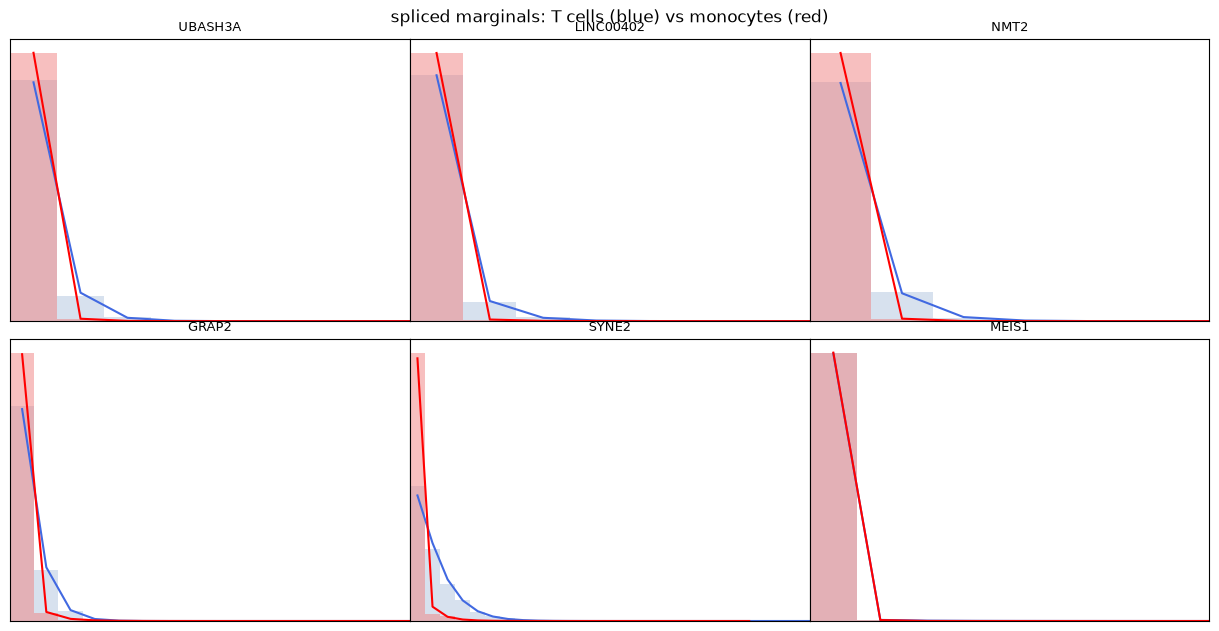

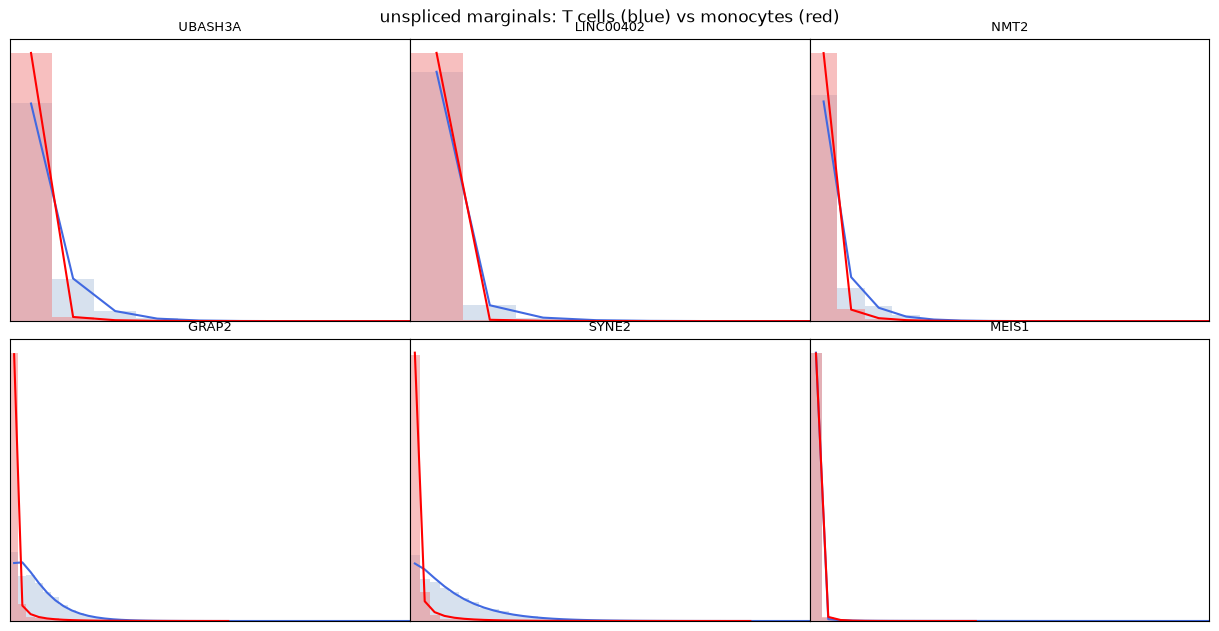

In [10]:
fc_cols = ['adj_FC_' + lab for lab in par_labels]
cand = tab.loc[tab['n_DE'] > 0] if (tab['n_DE'] > 0).any() else tab
top = cand.reindex(cand[fc_cols].abs().max(1).sort_values(ascending=False).index).head(6)
idx = np.array([list(adata_T.var_names).index(g) for g in top['gene']])
display(top[['gene'] + fc_cols + ['n_DE']].round(2).set_index('gene'))

for marg in ('spliced', 'unspliced'):
    analysis.compare_gene_distributions([sr_T, sr_M], [sd_T, sd_M], sz=(2, 3), figsize=(12, 6),
                                        marg=marg, genes_to_plot=idx)
    plt.suptitle(f'{marg} marginals: T cells (blue) vs monocytes (red)', y=1.02)
    plt.show()

---
## 9 · Saving and reloading

Everything above lives in the two `AnnData` objects as plain arrays and
dictionaries, so `write_h5ad` is all that is needed to keep it. Reading the file
back and calling `search_result_from_uns` restores the result object, including
the standard errors and the rejection flags.

In [11]:
out_dir = 'figures/analysis_workflow'
os.makedirs(out_dir, exist_ok=True)
adata_M.write_h5ad(f'{out_dir}/pbmc_monocytes_fit.h5ad')

back = ad.read_h5ad(f'{out_dir}/pbmc_monocytes_fit.h5ad')
sr_back = search_result_from_uns(back.uns['search_result'])
print('fold-change columns :', [c for c in back.var.columns if c.startswith('adj_FC_')])
print('rejected genes      :', int(sr_back.rejected_genes.sum()))
print('standard errors kept:', np.allclose(sr_back.sigma, sr_M.sigma))

fold-change columns : ['adj_FC_$b$', 'adj_FC_$\\beta$', 'adj_FC_$\\gamma$']
rejected genes      : 3
standard errors kept: True


---
## Summary

| Step | Call | Writes |
|---|---|---|
| Fit | `perform_inference(adata, model, exclude_sigma=False)` | `.var` parameters, `error_*`, `AIC`; `.uns['search_result']` |
| Rejection | `reject_genes(adata)` | `.var['rejected_genes', 'csq', 'pval', 'hellinger']` |
| Parameter DE | `DE_parameters(adata1, adata2)` | `.var['FC_*', 'adj_FC_*', 'adj_*']` |
| Mean DE | `diffexp_mean(sd1, sd2)` | returns flags and log2 fold changes |

The meK-Means variant of the same workflow, where the comparison runs between
clusters of a single dataset, is the subject of `mek_means.ipynb`.